In [1]:
import numpy as np
import matplotlib.pyplot as plt

import pywt

# Add files up one level to the path
import sys
sys.path.append("../..")

import scipy.sparse as sps
from scipy.fft import dct, idct
import jlinops

import pandas as pd

import sys
import os

from wavelets import WaveletTransformOperator2D


from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.ticker import FormatStrFormatter

import matplotlib as mpl
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.gridspec as gridspec
# mpl.rcParams['text.usetex'] = True
# mpl.rc('text.latex', preamble=r'\usepackage{amsmath}')

# Define the custom style with RGB color values
custom_style = {
    "axes.prop_cycle": plt.cycler(color=[(106/255, 192/255, 205/255),  # blue - C0
                                         (235/255, 186/255, 63/255),  # gold - C1
                                         (172/255, 46/255, 55/255),  # red - C2
                                         (32/255, 82/255, 145/255),  # dark blue - C3
                                         (83/255, 165/255, 106/255),  # green - C4
                                         (239/255, 145/255, 75/255),  # orange - C5
                                         (208/255, 92/255, 89/255),  # pink - C6
                                         (80/255, 67/255, 157/255),  # purple - C7
                                         (82/255, 82/255, 82/255),  # gray - C8
                                         (53/255, 53/255, 53/255),  # charcoal - C9
                                         (30/255, 27/255, 28/255), # black - C10  
                                         ]) 
}
plt.rc('axes', prop_cycle=custom_style['axes.prop_cycle'])


from msolver import VanillaGKS

# For reference, to match papers exactly:
# SGKS corresponds to msolver, MM2GKS ?
# SGKS (restarted) corresponds to msolver, MM1GKS
# SGKS (recycled) corresponds to msolver, MM2GKS ?
# PSGKS corresponds to msolver, MM2GKS
# PSGKB corresponds to pgkbsolver, MM2GKB
# FGK corresponds to fsolver, MM2FGK
# FLSQR-I corresponds to f2019solver, MM4FGK2019, with option I 
# FLSQR-R corresponds to f2019solver, MM4FGK2019, with option R
# FLSQR-W corresponds to f2019solver, MM4FGK2019, with option W <- we added this option ourselves, close to the method below
# IRW-FLSQR corresponds to fIRWsolver, MM2FGKIRW, with option IRW


from msolver import MM2GKS, MM1GKS, MM3GKS, MMXGKS
from pgkbsolver import MM3GKB, MMXGKB
from fsolver import MM3FGK, MMXFGK
from f2019solver import MM4FGK2019
from fIRWsolver import MM2FGKIRW


# Also the IAS imports
from msolver import IASGKS
from fsolver import IASFGK
from pgkbsolver import IASGKB
from f2019solver import IASFGK2019
from fIRWsolver import IASFGKIRW

In [2]:
image = np.zeros_like(jlinops.cameraman())
img_shape = image.shape
ground_truth = image.flatten()


# Perform 2D wavelet decomposition using Haar wavelet, with 3 levels
np.random.seed(0)
L = WaveletTransformOperator2D(img_shape, wavelet="haar", level=3)
coeffs = np.zeros(L.shape[0])
num_nonzero = 100
indices = np.random.choice(len(coeffs), size=num_nonzero, replace=False)
coeffs[indices] = 1
image = (L.T @ coeffs).reshape(img_shape)
ground_truth = image.flatten()


A = jlinops.Gaussian2DBlurOperator(img_shape, blur_sigma=2.0, mode="reflect")
#A = WaveletTransformOperator2D(img_shape, wavelet="haar", level=3)
b_true = A @ ground_truth
noise_level_sigma = 0.03
noise_vec = np.random.normal(size=A.shape[0])
noise_vec /= np.linalg.norm(noise_vec)
noise_vec *= noise_level_sigma*np.linalg.norm(b_true)
noise_var = ( (noise_level_sigma*np.linalg.norm(b_true) )**2 ) / A.shape[0]
noise_sigma = np.sqrt(noise_var)
b = b_true + noise_vec
naive_recon = A.T @ b

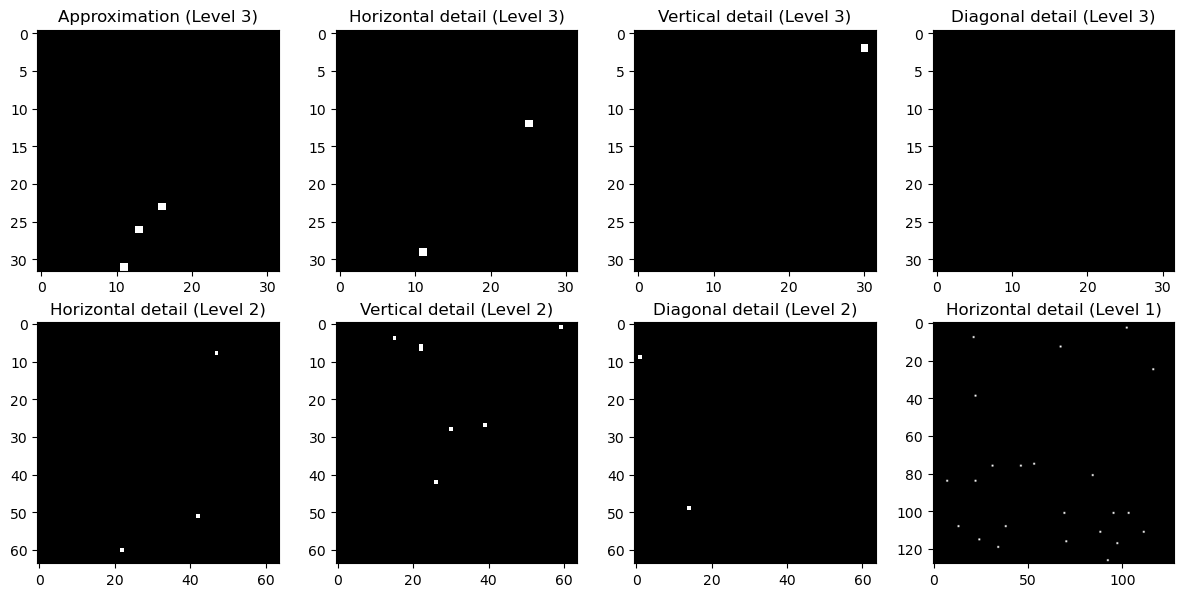

In [3]:
# Create a sample 2D image (e.g., 256x256 random matrix)

# Perform 2D wavelet decomposition using Haar wavelet, with 3 levels
coeffs = pywt.wavedec2(image, 'haar', level=3)

# coeffs is a list containing the approximation coefficients and detail coefficients
# The first element of coeffs is the approximation coefficient at level 3
# The subsequent elements are tuples of detail coefficients (horizontal, vertical, diagonal) for each level

# Extract the approximation coefficients at the final level (level 3)
cA3 = coeffs[0]

# Extract the detail coefficients (cH, cV, cD) for each level
(cH3, cV3, cD3), (cH2, cV2, cD2), (cH1, cV1, cD1) = coeffs[1:]

# Plotting the approximation and detail coefficients for visualization
fig, ax = plt.subplots(2, 4, figsize=(12, 6))

# Level 3 coefficients
ax[0, 0].imshow(cA3, cmap='gray')
ax[0, 0].set_title('Approximation (Level 3)')

ax[0, 1].imshow(cH3, cmap='gray')
ax[0, 1].set_title('Horizontal detail (Level 3)')

ax[0, 2].imshow(cV3, cmap='gray')
ax[0, 2].set_title('Vertical detail (Level 3)')

ax[0, 3].imshow(cD3, cmap='gray')
ax[0, 3].set_title('Diagonal detail (Level 3)')

# Level 2 coefficients
ax[1, 0].imshow(cH2, cmap='gray')
ax[1, 0].set_title('Horizontal detail (Level 2)')

ax[1, 1].imshow(cV2, cmap='gray')
ax[1, 1].set_title('Vertical detail (Level 2)')

ax[1, 2].imshow(cD2, cmap='gray')
ax[1, 2].set_title('Diagonal detail (Level 2)')

# Level 1 coefficients
ax[1, 3].imshow(cH1, cmap='gray')
ax[1, 3].set_title('Horizontal detail (Level 1)')

# Adjust layout and show the plot
plt.tight_layout()
plt.show()


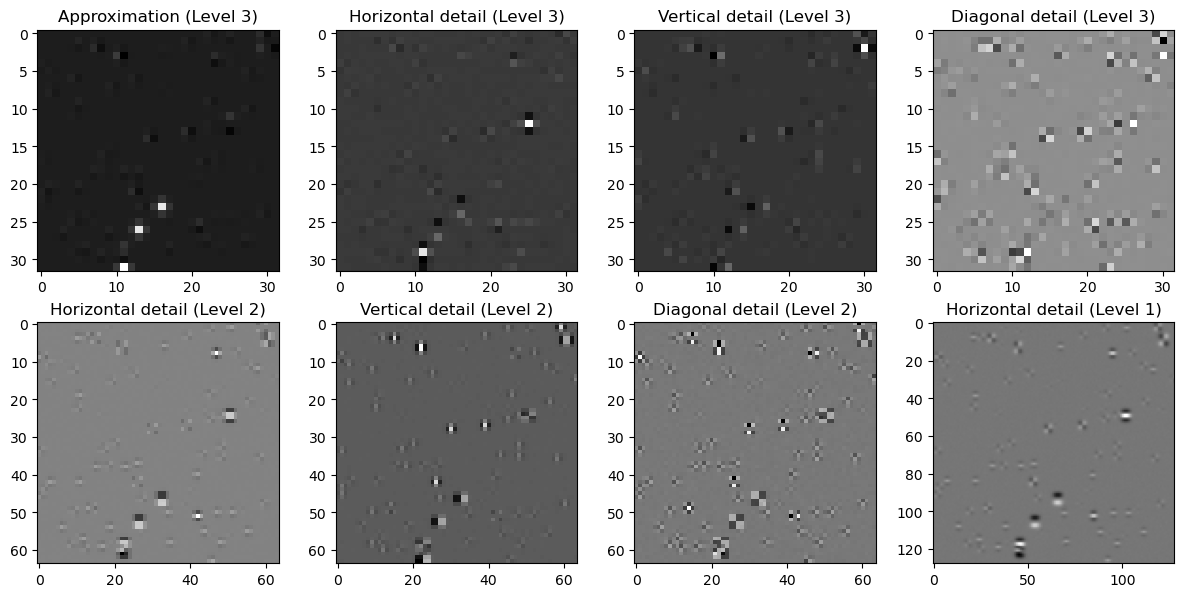

In [4]:
# Create a sample 2D image (e.g., 256x256 random matrix)

# Perform 2D wavelet decomposition using Haar wavelet, with 3 levels
coeffs = pywt.wavedec2(b.reshape(img_shape), 'haar', level=3)

# coeffs is a list containing the approximation coefficients and detail coefficients
# The first element of coeffs is the approximation coefficient at level 3
# The subsequent elements are tuples of detail coefficients (horizontal, vertical, diagonal) for each level

# Extract the approximation coefficients at the final level (level 3)
cA3 = coeffs[0]

# Extract the detail coefficients (cH, cV, cD) for each level
(cH3, cV3, cD3), (cH2, cV2, cD2), (cH1, cV1, cD1) = coeffs[1:]

# Plotting the approximation and detail coefficients for visualization
fig, ax = plt.subplots(2, 4, figsize=(12, 6))

# Level 3 coefficients
ax[0, 0].imshow(cA3, cmap='gray')
ax[0, 0].set_title('Approximation (Level 3)')

ax[0, 1].imshow(cH3, cmap='gray')
ax[0, 1].set_title('Horizontal detail (Level 3)')

ax[0, 2].imshow(cV3, cmap='gray')
ax[0, 2].set_title('Vertical detail (Level 3)')

ax[0, 3].imshow(cD3, cmap='gray')
ax[0, 3].set_title('Diagonal detail (Level 3)')

# Level 2 coefficients
ax[1, 0].imshow(cH2, cmap='gray')
ax[1, 0].set_title('Horizontal detail (Level 2)')

ax[1, 1].imshow(cV2, cmap='gray')
ax[1, 1].set_title('Vertical detail (Level 2)')

ax[1, 2].imshow(cD2, cmap='gray')
ax[1, 2].set_title('Diagonal detail (Level 2)')

# Level 1 coefficients
ax[1, 3].imshow(cH1, cmap='gray')
ax[1, 3].set_title('Horizontal detail (Level 1)')

# Adjust layout and show the plot
plt.tight_layout()
plt.show()


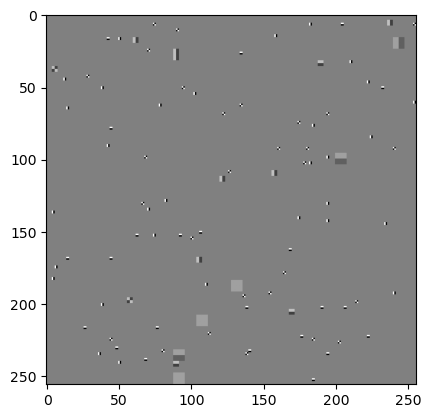

In [5]:
plt.imshow(image, cmap="gray")
plt.show()

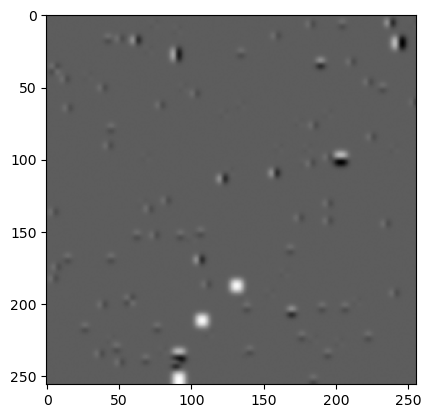

In [6]:
plt.imshow(b.reshape(img_shape), cmap="gray")
plt.show()

# Setup prior

In [7]:
# This can be figured out later
# mask = np.zeros(Lpre.shape[0])
# mask[ Lpre.detail_indices ] = 1
# P = jlinops.Subsampling1DOperator(mask)
#L = P @ Lpre

L = WaveletTransformOperator2D(img_shape, wavelet="haar", level=3)
K = None
Lpinv_factory = lambda wr: L.T @ jlinops.MatrixLinearOperator(sps.diags(1.0/wr))
Lpinv_factory2 = lambda wr: jlinops.MatrixLinearOperator(sps.diags(1.0/wr))

In [8]:

xker = None

# Weight params

mm_weight_params = {
    "q": 1.0,
}

ias_weight_params = {
    "hyperpr_r": -1,
    "hyperpr_beta": 1,
}


# Setup solvers

In [9]:
# Vanilla GKS
v_gks_solver = VanillaGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)

# MM weights
mm1_gks_solver = MM1GKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)
mm2_gks_solver = MM2GKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)
mm3_gks_solver = MM3GKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)
mmx_gks_solver = MMXGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)
mm3_fgk_solver = MM3FGK(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)
mmx_fgk_solver = MMXFGK(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)
mm4_fgk2019_solver = MM4FGK2019(A, L, L.T, b, noise_var=noise_var, K=K, img_shape=img_shape) # Options I, R, W
mm2_fgkirw_solver = MM2FGKIRW(A, L, L.T, b, noise_var=noise_var, K=K, img_shape=img_shape) # Option IRW
mm3_psgkb_solver = MM3GKB(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)
mmx_psgkb_solver = MMXGKB(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)

# IAS weights
ias_gks_solver = IASGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)
ias_fgk_solver = IASFGK(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)
ias_fgk2019_solver = IASFGK2019(A, L, L.T, b, noise_var=noise_var, K=K, img_shape=img_shape)
ias_fgkirw_solver = IASFGKIRW(A, L, L.T, b, noise_var=noise_var, K=K, img_shape=img_shape) # Option IRW
ias_psgkb_solver = IASGKB(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)

In [11]:
# Parameters
method = "dp"
n_its = 125
ksparsity = None
lambdah_min = 1e-7
lambdah_max = 1e7

fgk_breakdown_tol = 1e-15

In [12]:
%%capture 

### MM weights (2019 version)

all_v_results = []

# Vanilla GKS
v_gks_data = v_gks_solver.solve(n_iter=n_its, init_dim=5, x0=None, lambdah0=1e0, lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                    regparam=method, x_true=ground_truth, weight_params={}, ksparsity=ksparsity,
                                    regparam_kwargs={"eta":1.01},  xker=xker)

all_v_results.append( ( "V", "GKS", v_gks_data  ) )


all_mm_results = []

# S-GKS
mm_sgks_data = mm2_gks_solver.solve(n_iter=n_its, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                    regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mm_weight_params,
                                    regparam_kwargs={"eta":1.01}, min_dim=None, max_dim=None, xker=xker)

all_mm_results.append( ( "MM", "S-GKS", mm_sgks_data  ) )



# Recycled/restarted S-GKS
# mm_sgks_resdata = mm1_gks_solver.solve(n_iter=800, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
#                                     regparam=method, x_true=ground_truth, ksparsity=4, weight_params=mm_weight_params,
#                                     regparam_kwargs={"eta":1.01}, min_dim=None, max_dim=None, xker=xker, restart_dim=60)


# mm_sgks_recdata = mm2_gks_solver.solve(n_iter=800, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
#                                     regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mm_weight_params,
#                                     regparam_kwargs={"eta":1.01}, min_dim=30, max_dim=60, xker=xker, restart_dim=None)


# PS-GKS
mm_psgks_data = mmx_gks_solver.solve_with_priorconditioning(n_iter=n_its, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mm_weight_params, 
                                                 regparam_kwargs={"eta":1.01})

all_mm_results.append( ( "MM", "PS-GKS", mm_psgks_data  ) )

# PS-GKB
mm_psgkb_data = mmx_psgkb_solver.solve(n_iter=n_its, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"],
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mm_weight_params, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                 lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                #  init_dim=5
                                                 )

all_mm_results.append( ( "MM", "PS-GKB", mm_psgkb_data  ) )


# FGK
mm_fgk_data = mm3_fgk_solver.solve(n_iter=n_its, x0=None, lambdah0=None, breakdown_tol=fgk_breakdown_tol,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mm_weight_params, 
                                                 lambdah_min=lambdah_min, lambdah_max=lambdah_max, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                 )

all_mm_results.append( ( "MM", "FGK", mm_fgk_data  ) )



# FGK2019 (there are four versions to do here.)
mm_fgk2019I_data = mm4_fgk2019_solver.solve(n_iter=n_its, mode="I", x0=None, lambdah0=None, breakdown_tol=fgk_breakdown_tol,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mm_weight_params, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                 lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                #  init_dim=5
                                                 )

all_mm_results.append( ( "MM", "FLSQR-I", mm_fgk2019I_data  ) )


mm_fgk2019R_data = mm4_fgk2019_solver.solve(n_iter=n_its, mode="R", x0=None, lambdah0=None, breakdown_tol=fgk_breakdown_tol,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mm_weight_params, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                 lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                #  init_dim=5
                                                 )

all_mm_results.append( ( "MM", "FLSQR-R", mm_fgk2019R_data  ) )

mm_fgk2019W_data = mm4_fgk2019_solver.solve(n_iter=n_its, mode="W", x0=None, lambdah0=None, breakdown_tol=fgk_breakdown_tol,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mm_weight_params, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                 lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                #  init_dim=5
                                                 )

all_mm_results.append( ( "MM", "FLSQR-W", mm_fgk2019W_data  ) )



mm_fgk2019IRW_data = mm2_fgkirw_solver.solve(n_iter=n_its, mode="IRW", x0=None, lambdah0=None, breakdown_tol=fgk_breakdown_tol,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mm_weight_params, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                 lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                #  init_dim=5
                                                 )


all_mm_results.append( ( "MM", "IRW-FLSQR", mm_fgk2019IRW_data  ) )



In [13]:
%%capture 

### IAS weights


all_ias_results = []

# S-GKS
ias_sgks_data = ias_gks_solver.solve(n_iter=n_its, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                    regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=ias_weight_params,
                                    regparam_kwargs={"eta":1.01}, min_dim=None, max_dim=None, xker=xker)

all_ias_results.append( ( "IAS", "S-GKS", ias_sgks_data  ) )



# # Recycled/restarted S-GKS
# ias_sgks_resdata = ias_gks_solver.solve(n_iter=800, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
#                                     regparam=method, x_true=ground_truth, ksparsity=4, weight_params=ias_weight_params,
#                                     regparam_kwargs={"eta":1.01}, min_dim=None, max_dim=None, xker=xker, restart_dim=60)


# ias_sgks_recdata = ias_gks_solver.solve(n_iter=800, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
#                                     regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=ias_weight_params,
#                                     regparam_kwargs={"eta":1.01}, min_dim=30, max_dim=60, xker=xker, restart_dim=None)


# PS-GKS
ias_psgks_data = ias_gks_solver.solve_with_priorconditioning(n_iter=n_its, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=ias_weight_params, 
                                                 regparam_kwargs={"eta":1.01})

all_ias_results.append( ( "IAS", "PS-GKS", ias_psgks_data  ) )


ias_psgkb_data = ias_psgkb_solver.solve(n_iter=n_its, x0=None, lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=ias_weight_params, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                 lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                #  init_dim=5
                                                 )

all_ias_results.append( ( "IAS", "PS-GKB", ias_psgkb_data  ) )


# FGK
ias_fgk_data = ias_fgk_solver.solve(n_iter=n_its, x0=None, lambdah0=None, breakdown_tol=fgk_breakdown_tol,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=ias_weight_params, 
                                                 lambdah_min=lambdah_min, lambdah_max=lambdah_max, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                 )

all_ias_results.append( ( "IAS", "FGK", ias_fgk_data  ) )



# FGK2019 (there are four versions to do here.)
ias_fgk2019I_data = ias_fgk2019_solver.solve(n_iter=n_its, mode="I", x0=None, lambdah0=None, breakdown_tol=fgk_breakdown_tol,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=ias_weight_params, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                 lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                #  init_dim=5
                                                 )

all_ias_results.append( ( "IAS", "FLSQR-I", ias_fgk2019I_data  ) )


ias_fgk2019R_data = ias_fgk2019_solver.solve(n_iter=n_its, mode="R", x0=None, lambdah0=None, breakdown_tol=fgk_breakdown_tol,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=ias_weight_params, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                 lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                #  init_dim=5
                                                 )

all_ias_results.append( ( "IAS", "FLSQR-R", ias_fgk2019R_data  ) )

ias_fgk2019W_data = ias_fgk2019_solver.solve(n_iter=n_its, mode="W", x0=None, lambdah0=None, breakdown_tol=fgk_breakdown_tol,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=ias_weight_params, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                 lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                #  init_dim=5
                                                 )

all_ias_results.append( ( "IAS", "FLSQR-W", mm_fgk2019W_data  ) )



ias_fgk2019IRW_data = ias_fgkirw_solver.solve(n_iter=n_its, mode="IRW", x0=None, lambdah0=None, breakdown_tol=fgk_breakdown_tol,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=ias_weight_params, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                 lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                #  init_dim=5
                                                 )


all_ias_results.append( ( "IAS", "IRW-FLSQR", ias_fgk2019IRW_data  ) )





# Save and make tables

In [18]:
v_df = pd.DataFrame({"Weights":[], "Method":[], "lambdah":[], "RRE":[], "SSIM": [], "Gini index": [], "A matvecs": [], "L matvecs": [], "WLpinv matvecs": [], "n_iters": []  })

for set in all_v_results:
        weight_str, method_label, method_data = set
        new_df = pd.DataFrame({"Weights":[weight_str], "Method":[method_label], "lambdah":[ method_data["lambda_history"][-1] ], "RRE":[ method_data["rre_history"][-1] ], "SSIM": [ method_data["ssim_history"][-1] ], "Gini index": [ method_data["gini_indices"][-1] ], "A matvecs": [ method_data["tot_matvec_A"] ], "L matvecs": [ method_data["tot_matvec_L"] ], "WLpinv matvecs": [ method_data["tot_matvec_WLpinv"] ], "n_iters": [ method_data["n_completed_iterations"] ]  })
        v_df = pd.concat([v_df, new_df], axis=0)


mm_df = pd.DataFrame({"Weights":[], "Method":[], "lambdah":[], "RRE":[], "SSIM": [], "Gini index": [], "Hoyer index": [], "A matvecs": [], "L matvecs": [], "WLpinv matvecs": []})

for set in all_mm_results:
        weight_str, method_label, method_data = set
        new_df = pd.DataFrame({"Weights":[weight_str], "Method":[method_label], "lambdah":[ method_data["lambda_history"][-1] ], "RRE":[ method_data["rre_history"][-1] ], "SSIM": [ method_data["ssim_history"][-1] ], "Gini index": [ method_data["gini_indices"][-1] ], "Hoyer index": [ method_data["hoyer_indices"][-1] ], "A matvecs": [ method_data["tot_matvec_A"] ], "L matvecs": [ method_data["tot_matvec_L"] ], "WLpinv matvecs": [ method_data["tot_matvec_WLpinv"] ], "n_iters": [ method_data["n_completed_iterations"] ]  })
        mm_df = pd.concat([mm_df, new_df], axis=0)



ias_df = pd.DataFrame({"Weights":[], "Method":[], "lambdah":[], "RRE":[], "SSIM": [], "Gini index": [], "Hoyer index": [], "A matvecs": [], "L matvecs": [], "WLpinv matvecs": []})

for set in all_ias_results:
        weight_str, method_label, method_data = set
        new_df = pd.DataFrame({"Weights":[weight_str], "Method":[method_label], "lambdah":[ method_data["lambda_history"][-1] ], "RRE":[ method_data["rre_history"][-1] ], "SSIM": [ method_data["ssim_history"][-1] ], "Gini index": [ method_data["gini_indices"][-1] ], "Hoyer index": [ method_data["hoyer_indices"][-1] ], "A matvecs": [ method_data["tot_matvec_A"] ], "L matvecs": [ method_data["tot_matvec_L"] ], "WLpinv matvecs": [ method_data["tot_matvec_WLpinv"] ], "n_iters": [ method_data["n_completed_iterations"] ] })
        ias_df = pd.concat([ias_df, new_df], axis=0)

In [19]:
all_df = pd.concat([v_df, mm_df, ias_df])
all_df = all_df[["Weights", "Method", "lambdah", "n_iters", "RRE", "SSIM", "Gini index", "A matvecs", "L matvecs", "WLpinv matvecs"]]
all_df = all_df.rename(columns={'lambdah': '$\lambda$', "n_iters":"$n_{\\textrm{iter}}$", "A matvecs":"$n_{\mathbf{A}}$", "L matvecs":"$n_{\mathbf{L}}$", "WLpinv matvecs":"$n_{\mathbf{ L }_k^\dagger }$"  })
all_df.to_csv("2d_wavelet_randhaar_performance_results.csv")
all_df

,Weights,Method,$\lambda$,$n_{\textrm{iter}}$,RRE,SSIM,Gini index,$n_{\mathbf{A}}$,$n_{\mathbf{L}}$,$n_{\mathbf{ L }_k^\dagger }$
0,V,GKS,7.734696e+03,125.0,0.915749,0.906213,0.736888,265.0,380.0,0.0
0,MM,S-GKS,3.985389e+02,125.0,0.882440,0.916412,0.780070,265.0,381.0,0.0
0,MM,PS-GKS,7.410298e+02,125.0,0.611166,0.964238,0.954289,17009.0,128.0,17135.0
0,MM,PS-GKB,8.068075e+02,125.0,0.581357,0.968192,0.953566,15750.0,126.0,15875.0
0,MM,FGK,1.000000e-07,125.0,0.728332,0.940886,0.974062,251.0,251.0,250.0
0,MM,FLSQR-I,8.879924e+01,125.0,0.870920,0.919537,0.909302,251.0,1.0,376.0
0,MM,FLSQR-R,5.589490e+03,125.0,0.870018,0.919828,0.908925,251.0,1.0,376.0
0,MM,FLSQR-W,2.709241e+02,125.0,0.872743,0.919035,0.912561,251.0,1.0,376.0
0,MM,IRW-FLSQR,6.083512e+02,125.0,0.862214,0.921675,0.782937,251.0,1.0,376.0
0,IAS,S-GKS,9.180972e+04,125.0,0.825272,0.928482,0.887160,265.0,381.0,0.0


In [20]:
def scientific_to_latex(sci_str):
    # Split the number into base and exponent parts
    sci_str = f"{sci_str:.0e}"
    base, exponent = sci_str.split('e')
    
    # Convert base to integer (since the decimal places can be ignored)
    base = str(int(float(base)))
    
    # Prepare the exponent part, removing the leading "+" if it's a positive exponent
    exponent = exponent.lstrip("+")
    
    # Format the result as a LaTeX string
    latex_str = f"${base}\\cdot10^{{{int(exponent)}}}$"
    
    return latex_str

In [21]:
print( all_df.to_latex(index=False, formatters={'$\lambda$': lambda s: scientific_to_latex(s), 
                                                "RRE": "${:.3f}$", "SSIM": "${:.3f}$", 
                                                  "Gini index": "${:.3f}$", "Hoyer index": "${:.3f}$", 
                                                  "$n_{\\textrm{iter}}$": "${:.0f}$",
                                                  "$n_{\mathbf{A}}$": "${:.0f}$", "$n_{\mathbf{L}}$": "${:.0f}$", "$n_{\mathbf{ L }_k^\dagger }$": "${:.0f}$"
                                                    }) )

\begin{tabular}{llrrrrrrrr}
\toprule
Weights & Method & $\lambda$ & $n_{\textrm{iter}}$ & RRE & SSIM & Gini index & $n_{\mathbf{A}}$ & $n_{\mathbf{L}}$ & $n_{\mathbf{ L }_k^\dagger }$ \\
\midrule
V & GKS & $8\cdot10^{3}$ & $125$ & $0.916$ & $0.906$ & $0.737$ & $265$ & $380$ & $0$ \\
MM & S-GKS & $4\cdot10^{2}$ & $125$ & $0.882$ & $0.916$ & $0.780$ & $265$ & $381$ & $0$ \\
MM & PS-GKS & $7\cdot10^{2}$ & $125$ & $0.611$ & $0.964$ & $0.954$ & $17009$ & $128$ & $17135$ \\
MM & PS-GKB & $8\cdot10^{2}$ & $125$ & $0.581$ & $0.968$ & $0.954$ & $15750$ & $126$ & $15875$ \\
MM & FGK & $1\cdot10^{-7}$ & $125$ & $0.728$ & $0.941$ & $0.974$ & $251$ & $251$ & $250$ \\
MM & FLSQR-I & $9\cdot10^{1}$ & $125$ & $0.871$ & $0.920$ & $0.909$ & $251$ & $1$ & $376$ \\
MM & FLSQR-R & $6\cdot10^{3}$ & $125$ & $0.870$ & $0.920$ & $0.909$ & $251$ & $1$ & $376$ \\
MM & FLSQR-W & $3\cdot10^{2}$ & $125$ & $0.873$ & $0.919$ & $0.913$ & $251$ & $1$ & $376$ \\
MM & IRW-FLSQR & $6\cdot10^{2}$ & $125$ & $0.862$ & $0.922

# Reconstruction plots

In [22]:
from skimage.metrics import structural_similarity

In [24]:
np.amax(ground_truth)

0.5000000000000001

In [25]:
np.amin(ground_truth)

-0.5000000000000001

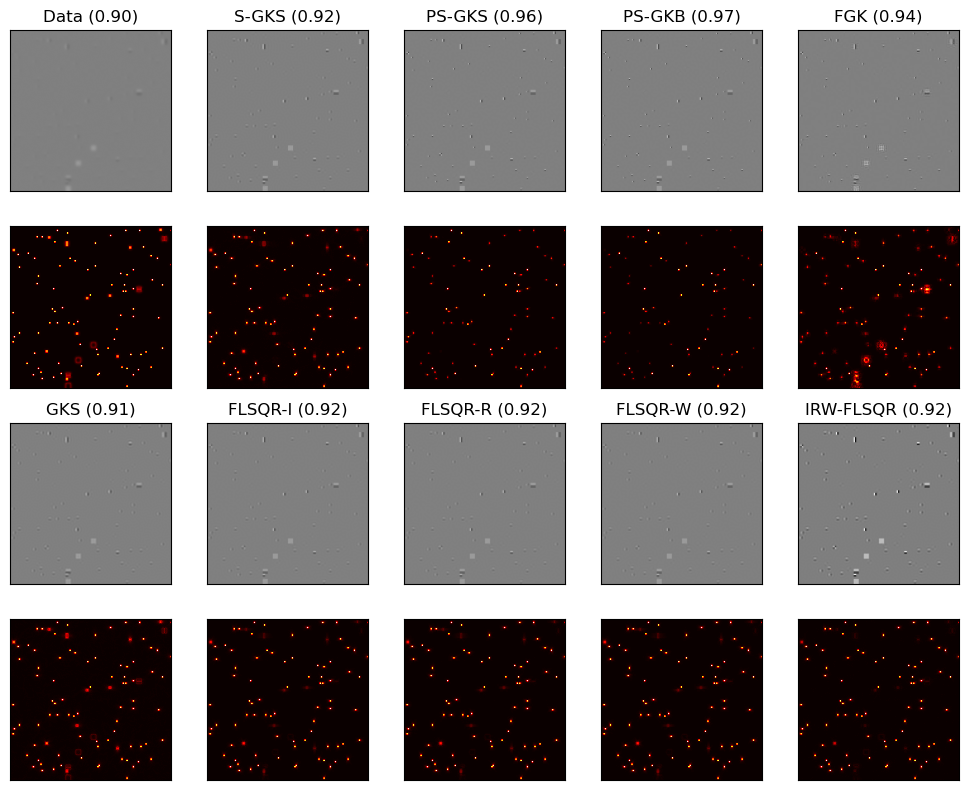

In [26]:
err_cmap = "hot"

vbound = 0.4
vmin = -0.6
vmax = 0.6
metric = "ssim_history"

fig, axs = plt.subplots(4,5,figsize=(10,8))


# Observed
perf_metric = structural_similarity( b.reshape(img_shape), ground_truth.reshape(img_shape), data_range=(np.amax(ground_truth) - np.amin(ground_truth) ), gaussian_weights=True, sigma=1.5, use_sample_covariance=False )
axs[0,0].imshow(b.reshape(img_shape), cmap="gray", vmin=vmin, vmax=vmax)
axs[0,0].set_title(f"Data ({perf_metric:.2f})")
axs[0,0].set_xticks([])
axs[0,0].set_yticks([])

axs[1,0].imshow(np.abs( b.reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,0].set_xticks([])
axs[1,0].set_yticks([])


# V-GKS
axs[2,0].imshow(v_gks_data["x"].reshape(img_shape), cmap="gray", vmin=vmin, vmax=vmax)
perf_metric = v_gks_data[metric][-1]
axs[2,0].set_title(f"GKS ({perf_metric:.2f})")
axs[2,0].set_xticks([])
axs[2,0].set_yticks([])

axs[3,0].imshow(np.abs( v_gks_data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[3,0].set_xticks([])
axs[3,0].set_yticks([])


# S-GKS
axs[0,1].imshow(mm_sgks_data["x"].reshape(img_shape), cmap="gray", vmin=vmin, vmax=vmax)
perf_metric = mm_sgks_data[metric][-1]
axs[0,1].set_title(f"S-GKS ({perf_metric:.2f})")
axs[0,1].set_xticks([])
axs[0,1].set_yticks([])

axs[1,1].imshow(np.abs( mm_sgks_data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,1].set_xticks([])
axs[1,1].set_yticks([])



# PS-GKS
axs[0,2].imshow(mm_psgks_data["x"].reshape(img_shape), cmap="gray", vmin=vmin, vmax=vmax)
perf_metric = mm_psgks_data[metric][-1]
axs[0,2].set_title(f"PS-GKS ({perf_metric:.2f})")
axs[0,2].set_xticks([])
axs[0,2].set_yticks([])

axs[1,2].imshow(np.abs( mm_psgks_data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,2].set_xticks([])
axs[1,2].set_yticks([])


# PS-GKS
axs[0,3].imshow(mm_psgkb_data["x"].reshape(img_shape), cmap="gray", vmin=vmin, vmax=vmax)
perf_metric = mm_psgkb_data[metric][-1]
axs[0,3].set_title(f"PS-GKB ({perf_metric:.2f})")
axs[0,3].set_xticks([])
axs[0,3].set_yticks([])

axs[1,3].imshow(np.abs( mm_psgkb_data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,3].set_xticks([])
axs[1,3].set_yticks([])


# FGK
axs[0,4].imshow(mm_fgk_data["x"].reshape(img_shape), cmap="gray", vmin=vmin, vmax=vmax)
perf_metric = mm_fgk_data[metric][-1]
axs[0,4].set_title(f"FGK ({perf_metric:.2f})")
axs[0,4].set_xticks([])
axs[0,4].set_yticks([])

axs[1,4].imshow(np.abs( mm_fgk_data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,4].set_xticks([])
axs[1,4].set_yticks([])


# LSQR-I
axs[2,1].imshow(mm_fgk2019I_data["x"].reshape(img_shape), cmap="gray", vmin=vmin, vmax=vmax)
perf_metric = mm_fgk2019I_data[metric][-1]
axs[2,1].set_title(f"FLSQR-I ({perf_metric:.2f})")
axs[2,1].set_xticks([])
axs[2,1].set_yticks([])

axs[3,1].imshow(np.abs( mm_fgk2019I_data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[3,1].set_xticks([])
axs[3,1].set_yticks([])



# LSQR-R
axs[2,2].imshow(mm_fgk2019R_data["x"].reshape(img_shape), cmap="gray", vmin=vmin, vmax=vmax)
perf_metric = mm_fgk2019R_data[metric][-1]
axs[2,2].set_title(f"FLSQR-R ({perf_metric:.2f})")
axs[2,2].set_xticks([])
axs[2,2].set_yticks([])

axs[3,2].imshow(np.abs( mm_fgk2019R_data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[3,2].set_xticks([])
axs[3,2].set_yticks([])


# LSQR-W
axs[2,3].imshow(mm_fgk2019W_data["x"].reshape(img_shape), cmap="gray", vmin=vmin, vmax=vmax)
perf_metric = mm_fgk2019W_data[metric][-1]
axs[2,3].set_title(f"FLSQR-W ({perf_metric:.2f})")
axs[2,3].set_xticks([])
axs[2,3].set_yticks([])

axs[3,3].imshow(np.abs( mm_fgk2019W_data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[3,3].set_xticks([])
axs[3,3].set_yticks([])




# IRW-LSQR
axs[2,4].imshow(mm_fgk2019IRW_data["x"].reshape(img_shape), cmap="gray")
perf_metric = mm_fgk2019IRW_data[metric][-1]
axs[2,4].set_title(f"IRW-FLSQR ({perf_metric:.2f})")
axs[2,4].set_xticks([])
axs[2,4].set_yticks([])

axs[3,4].imshow(np.abs( mm_fgk2019IRW_data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[3,4].set_xticks([])
axs[3,4].set_yticks([])




fig.tight_layout()

fig.savefig("2d_wavelet_randhaar_reconstructions_mm.png", dpi=250, bbox_inches=None)
fig.savefig("2d_wavelet_randhaar_reconstructions_mm.eps", format="eps", dpi=250, bbox_inches=None)


plt.show()

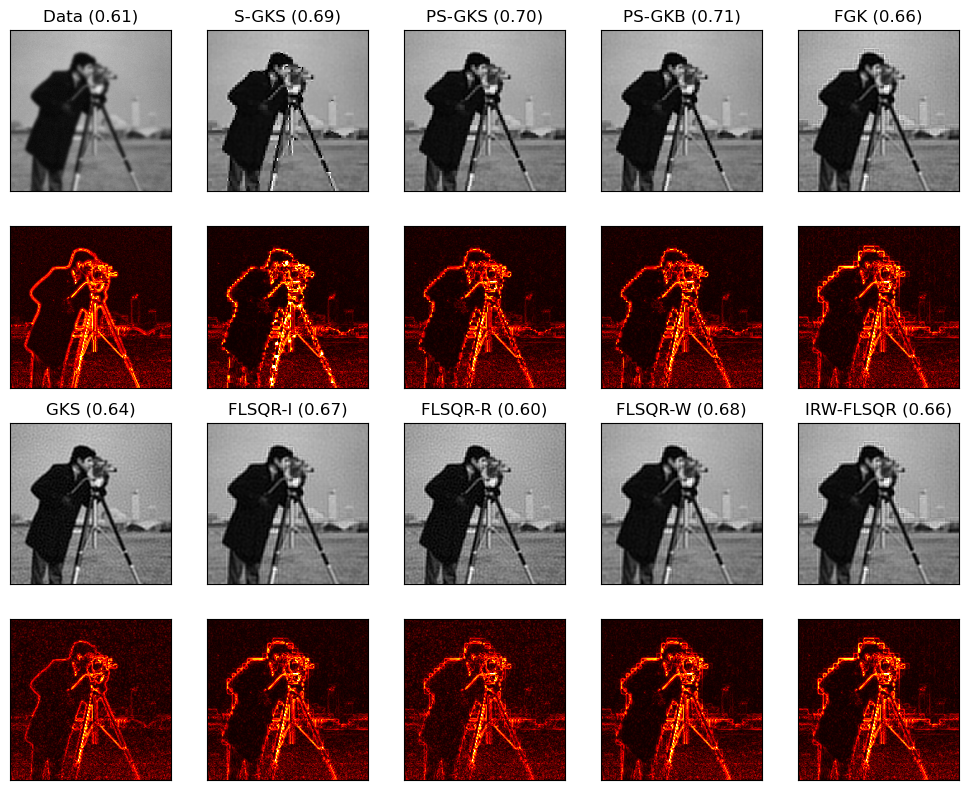

In [35]:
err_cmap = "hot"

vbound = 0.4
vmin = -0.6
vmax = 0.6
metric = "ssim_history"

fig, axs = plt.subplots(4,5,figsize=(10,8))


# Observed
perf_metric = structural_similarity( b.reshape(img_shape), ground_truth.reshape(img_shape), data_range=(np.amax(ground_truth) - np.amin(ground_truth) ), gaussian_weights=True, sigma=1.5, use_sample_covariance=False )
axs[0,0].imshow(b.reshape(img_shape), cmap="gray", vmin=vmin, vmax=vmax)
axs[0,0].set_title(f"Data ({perf_metric:.2f})")
axs[0,0].set_xticks([])
axs[0,0].set_yticks([])

axs[1,0].imshow(np.abs( b.reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,0].set_xticks([])
axs[1,0].set_yticks([])


# V-GKS
axs[2,0].imshow(v_gks_data["x"].reshape(img_shape), cmap="gray", vmin=vmin, vmax=vmax)
perf_metric = v_gks_data[metric][-1]
axs[2,0].set_title(f"GKS ({perf_metric:.2f})")
axs[2,0].set_xticks([])
axs[2,0].set_yticks([])

axs[3,0].imshow(np.abs( v_gks_data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[3,0].set_xticks([])
axs[3,0].set_yticks([])


# S-GKS
axs[0,1].imshow(ias_sgks_data["x"].reshape(img_shape), cmap="gray", vmin=vmin, vmax=vmax)
perf_metric = ias_sgks_data[metric][-1]
axs[0,1].set_title(f"S-GKS ({perf_metric:.2f})")
axs[0,1].set_xticks([])
axs[0,1].set_yticks([])

axs[1,1].imshow(np.abs( ias_sgks_data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,1].set_xticks([])
axs[1,1].set_yticks([])



# PS-GKS
axs[0,2].imshow(ias_psgks_data["x"].reshape(img_shape), cmap="gray", vmin=vmin, vmax=vmax)
perf_metric = ias_psgks_data[metric][-1]
axs[0,2].set_title(f"PS-GKS ({perf_metric:.2f})")
axs[0,2].set_xticks([])
axs[0,2].set_yticks([])

axs[1,2].imshow(np.abs( ias_psgks_data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,2].set_xticks([])
axs[1,2].set_yticks([])


# PS-GKS
axs[0,3].imshow(ias_psgkb_data["x"].reshape(img_shape), cmap="gray", vmin=vmin, vmax=vmax)
perf_metric = ias_psgkb_data[metric][-1]
axs[0,3].set_title(f"PS-GKB ({perf_metric:.2f})")
axs[0,3].set_xticks([])
axs[0,3].set_yticks([])

axs[1,3].imshow(np.abs( ias_psgkb_data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,3].set_xticks([])
axs[1,3].set_yticks([])


# FGK
axs[0,4].imshow(ias_fgk_data["x"].reshape(img_shape), cmap="gray", vmin=vmin, vmax=vmax)
perf_metric = ias_fgk_data[metric][-1]
axs[0,4].set_title(f"FGK ({perf_metric:.2f})")
axs[0,4].set_xticks([])
axs[0,4].set_yticks([])

axs[1,4].imshow(np.abs( ias_fgk_data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,4].set_xticks([])
axs[1,4].set_yticks([])


# LSQR-I
axs[2,1].imshow(ias_fgk2019I_data["x"].reshape(img_shape), cmap="gray", vmin=vmin, vmax=vmax)
perf_metric = ias_fgk2019I_data[metric][-1]
axs[2,1].set_title(f"FLSQR-I ({perf_metric:.2f})")
axs[2,1].set_xticks([])
axs[2,1].set_yticks([])

axs[3,1].imshow(np.abs( ias_fgk2019I_data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[3,1].set_xticks([])
axs[3,1].set_yticks([])



# LSQR-R
axs[2,2].imshow(ias_fgk2019R_data["x"].reshape(img_shape), cmap="gray", vmin=vmin, vmax=vmax)
perf_metric = ias_fgk2019R_data[metric][-1]
axs[2,2].set_title(f"FLSQR-R ({perf_metric:.2f})")
axs[2,2].set_xticks([])
axs[2,2].set_yticks([])

axs[3,2].imshow(np.abs( ias_fgk2019R_data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[3,2].set_xticks([])
axs[3,2].set_yticks([])


# LSQR-W
axs[2,3].imshow(ias_fgk2019W_data["x"].reshape(img_shape), cmap="gray", vmin=vmin, vmax=vmax)
perf_metric = ias_fgk2019W_data[metric][-1]
axs[2,3].set_title(f"FLSQR-W ({perf_metric:.2f})")
axs[2,3].set_xticks([])
axs[2,3].set_yticks([])

axs[3,3].imshow(np.abs( ias_fgk2019W_data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[3,3].set_xticks([])
axs[3,3].set_yticks([])




# IRW-LSQR
axs[2,4].imshow(ias_fgk2019IRW_data["x"].reshape(img_shape), cmap="gray", vmin=vmin, vmax=vmax)
perf_metric = ias_fgk2019IRW_data[metric][-1]
axs[2,4].set_title(f"IRW-FLSQR ({perf_metric:.2f})")
axs[2,4].set_xticks([])
axs[2,4].set_yticks([])

axs[3,4].imshow(np.abs( ias_fgk2019IRW_data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[3,4].set_xticks([])
axs[3,4].set_yticks([])



fig.tight_layout()

fig.savefig("2d_wavelet_randhaar_reconstructions_ias.png", dpi=250, bbox_inches="tight")
fig.savefig("2d_wavelet_randhaar_reconstructions_ias.eps", format="eps", dpi=250, bbox_inches="tight")


plt.show()